In [ ]:
# ============================================================
# GGR376H5 Final Project
# ============================================================


In [ ]:
# STARTTTTTTT HEREEEE

In [ ]:
# Import Libraries
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, zipfile, io
from libpysal.weights import Queen, lag_spatial
from esda.moran import Moran, Moran_Local, Moran_BV, Moran_Local_BV
import matplotlib.patches as mpatches
from inequality.gini import Gini



sns.set(style="whitegrid")

In [ ]:
# ============================================================
# Data Collection and Processing [exploratory data analysis]
# ============================================================

# Load dataset from GitHun (Raw version) and read the csv file
df = pd.read_csv("https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/newdiabetesdata.csv")

# View first 5 rows
df.head()

,FID,spatial_id,name,Raw Diabetes,Diabetes Percentage,CDName
0,0,5350001.0,"CT0001.00, Toronto, ON",44,7.7465,Toronto
1,1,5350002.0,"CT0002.00, Toronto, ON",91,12.0211,Toronto
2,2,5350003.0,"CT0003.00, Toronto, ON",27,2.5093,Toronto
3,3,5350004.0,"CT0004.00, Toronto, ON",600,9.7260,Toronto
4,4,5350005.0,"CT0005.00, Toronto, ON",346,4.5550,Toronto


In [ ]:
# Check dataset dimensions (rows, columns)
df.shape

# View column names
df.columns

# View data types and missing values
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065 entries, 0 to 1064
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   FID                  1065 non-null   int64  
 1   spatial_id           1065 non-null   float64
 2   name                 1065 non-null   object 
 3   Raw Diabetes         1065 non-null   int64  
 4   Diabetes Percentage  1065 non-null   float64
 5   CDName               1065 non-null   object 
dtypes: float64(2), int64(2), object(2)
memory usage: 50.1+ KB


In [ ]:
# check if there are any null values
df.isnull().sum()

# there are no null values

,0
FID,0
spatial_id,0
name,0
Raw Diabetes,0
Diabetes Percentage,0
CDName,0


In [ ]:
# Summary statistics for Diabetes Percentage

df["Diabetes Percentage"].describe()




,Diabetes Percentage
count,1065.000000
mean,7.765004
std,4.050697
min,0.000000
25%,4.404400
50%,7.820600
75%,10.751100
max,19.189200


In [ ]:
# plt.figure(figsize=(7,5))

# sns.boxplot(y=df["Diabetes Percentage"], color="#4C72B0", showmeans=True,
#     meanprops={"marker": "x", "markeredgecolor": "black", "markersize": 8}
# )

# sns.despine()

# plt.title("Distribution of Diabetes (Type I and Type II) Across GTA Census Tracts", fontsize=12)
# plt.ylabel("Diabetes Rate (%)")
# plt.xlabel("")

# plt.show()

/tmp/ipykernel_3511/1666061636.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="CDName", y="Diabetes Percentage", data=df,


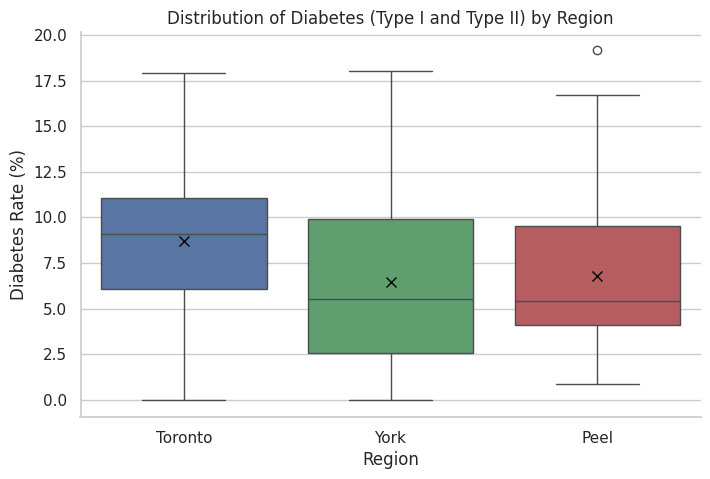

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x="CDName", y="Diabetes Percentage", data=df,
palette=["#4C72B0", "#55A868", "#C44E52"], showmeans=True,
    meanprops={"marker": "x", "markeredgecolor": "black", "markersize": 7}
)

sns.despine()

plt.title("Distribution of Diabetes (Type I and Type II) by Region")
plt.xlabel("Region")
plt.ylabel("Diabetes Rate (%)")

plt.show()

In [ ]:
df_summary = (
    df.groupby("CDName", as_index=False)
      .agg(
          n_tracts=("FID", "size"),
          mean_percentage=("Diabetes Percentage", "mean"),
          max_percentage=("Diabetes Percentage", "max"),
          median_percentage=("Diabetes Percentage", "median"),
      )
)


print("Summary output by Region")
print(type(df_summary))
try:
    display(df_summary)
except Exception as e:
    print("Could not display df_summary:", e)

Summary output by Region
<class 'pandas.core.frame.DataFrame'>


,CDName,n_tracts,mean_percentage,max_percentage,median_percentage
0,Peel,282,6.800154,19.1892,5.39735
1,Toronto,585,8.679399,17.9148,9.11230
2,York,198,6.437566,18.0485,5.54165


In [ ]:
# Load dataset from GitHun (Raw version) and read the csv file for recreational spaces
df_spaces = pd.read_csv(
    "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/ODRSF_v1.0.csv",
    encoding="cp1252",
    low_memory=False
)
df_spaces = df_spaces[df_spaces["Prov_Terr"] == "on"].copy()
df_spaces = df_spaces.reset_index(drop=True)



#filter for only cities of interest
keep_cities = [
    "Caledon",
    "Mississauga",
    "Brampton",
    "Toronto",
    "Georgina",
    "East Gwillimbury",
    "King",
    "Newmarket",
    "Aurora",
    "Richmond Hill",
    "Vaughan",
    "Markham",
    "Whitchurch-Stouffville"
]

df_spaces = df_spaces[df_spaces["CSD_Name"].isin(keep_cities)].copy()
df_spaces = df_spaces.reset_index(drop=True)


#display what types of facilities there are
"""facility_domain = sorted(df_spaces["ODRSF_facility_type"].dropna().unique().tolist())

for i, value in enumerate(facility_domain, start=1):
    print(f"{i}. {value}")
"""
#filter for only facilities of interest
keep_facilities = [
    "arena",
    "beach",
    "community centre",
    "gym",
    "marina",
    "miscellaneous",
    "park",
    "playground",
    "pool",
    "rink",
    "splash pad",
    "sports field",
    "stadium",
    "trail"
]

# filter for only facilities of interest
df_spaces = df_spaces[df_spaces["ODRSF_facility_type"].isin(keep_facilities)].copy()
df_spaces = df_spaces.reset_index(drop=True)

df_spaces["Longitude"] = pd.to_numeric(df_spaces["Longitude"], errors="coerce")
df_spaces["Latitude"] = pd.to_numeric(df_spaces["Latitude"], errors="coerce")

# View first 5 rows
df_spaces.head()

"""
# download the cleaned dataset
df_spaces.to_csv("cleaned_recreational_spaces.csv", index=False)

print("File saved as cleaned_recreational_spaces.csv")

from google.colab import files
files.download("cleaned_recreational_spaces.csv")
"""

'\n# download the cleaned dataset\ndf_spaces.to_csv("cleaned_recreational_spaces.csv", index=False)\n\nprint("File saved as cleaned_recreational_spaces.csv")\n\nfrom google.colab import files\nfiles.download("cleaned_recreational_spaces.csv")\n'

In [ ]:
# Load dataset from GitHub (Raw version) and read the csv file for median income
df_income = pd.read_csv(
    "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/refs/heads/main/Median%20Income%20Simply.csv",
    encoding="cp1252",
    low_memory=False
)

# define the column
column = "Households by Income (Current Year) | Median Household Income (Current Year $), 2025"

# remove spaces
df_income[column] = df_income[column].astype(str).str.strip()

# convert empty to NaN values doen by pandas
df_income[column] = df_income[column].replace("", pd.NA)


# check column names
# df_income.columns

# keep a copy of the original file
df_income_copy = df_income.copy()

# Convert the income column to numeric
df_income[column] = pd.to_numeric(df_income[column], errors="coerce")

# Remove rows where income is null and 0s
df_income = df_income.dropna(subset=[column]).copy()
df_income = df_income[df_income[column] != 0].copy()


# Reset index
df_income = df_income.reset_index(drop=True)

# Check
# df_income.head()

"""
# download the cleaned dataset
df_income.to_csv("cleaned_median_income.csv", index=False)

print("File saved as cleaned_median_income.csv")

from google.colab import files
files.download("cleaned_median_income.csv")
"""



'\n# download the cleaned dataset\ndf_income.to_csv("cleaned_median_income.csv", index=False)\n\nprint("File saved as cleaned_median_income.csv")\n\nfrom google.colab import files\nfiles.download("cleaned_median_income.csv")\n'

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np

# # Load  cleaned file
# df_spaces = pd.read_csv("https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/cleaned_bound_spaces.csv")

# # Keep only rows where census tract and diabetes % are present
# df_spaces = df_spaces.dropna(subset=["name", "VALUE3"]).copy()

# # Summarize by census tract
# tract_summary = (
#     df_spaces.groupby("name")
#     .agg(
#         num_spaces=("OBJECTID", "count"),   # number of recreational spaces in tract
#         diabetes_pct=("VALUE3", "first")    # diabetes percentage for that tract
#     )
#     .reset_index()
# )

# # View first few rows of the tract-level summary
# tract_summary.head()

# # Correlation ebtwe
# corr = tract_summary["num_spaces"].corr(tract_summary["diabetes_pct"])
# print("Correlation:", corr)

# # Scatter plot with line of best fit
# x = tract_summary["num_spaces"]
# y = tract_summary["diabetes_pct"]

# m, b = np.polyfit(x, y, 1)

# plt.figure(figsize=(8,6))
# plt.scatter(x, y, alpha=0.7)
# plt.plot(x, m*x + b)

# plt.xlabel("Number of recreational spaces in census tract")
# plt.ylabel("Diabetes percentage")
# plt.title("Relationship between recreational spaces and diabetes percentage")

# plt.show()

In [ ]:
# #RECREATIONAL ANALYSIS OF EVERYTHING

# from libpysal.weights import Queen
# from esda.moran import Moran, Moran_BV, Moran_Local, Moran_Local_BV
# import warnings
# warnings.filterwarnings("ignore")
# import scipy.stats as stats # Import scipy.stats
# import matplotlib.patches as mpatches

# print("Libraries loaded.")


# # Step 1 — Load Data
# # cleaned_bound_spaces.csv — spatially joined file: each rec facility tagged to its CT
# # census_tract_clipped.zip — CT polygon boundaries for Queen contiguity weights

# # Joined rec spaces + diabetes data
# df = pd.read_csv(
#     "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/cleaned_bound_spaces.csv"
# )
# df = df.dropna(subset=["name", "VALUE3"]).copy()
# # print(df.columns)
# # CT boundary shapefile (upload to same directory or adjust path)
# gdf = gpd.read_file("zip+https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/census_tract_clipped.zip", engine="pyogrio")

# print(f"Rec space rows : {len(df):,}")
# print(f"CT polygons    : {len(gdf):,}")
# print(f"Shapefile CRS  : {gdf.crs}")


# # Step 2 — Aggregate to Census Tract Level
# # Group rec space rows by spatial_id (CT UID) to get facility count and diabetes % per tract.

# tract_summary = (
#     df.groupby("spatial_id")
#     .agg(
#         num_spaces   = ("OBJECTID", "count"),
#         diabetes_pct = ("VALUE3",   "first"),
#     )
#     .reset_index()
# )

# print(f"Census tracts in summary: {len(tract_summary)}")
# tract_summary.describe()


# # Step 3 — Join Tract Summary to CT Polygons
# # Merge the tract-level data onto the shapefile using CTUID ↔ spatial_id. Reproject to UTM Zone 17N (EPSG:32617) for accurate distance calculations.

# # Standardise CTUID to float for matching
# gdf["CTUID_float"] = gdf["CTUID"].astype(float)

# # Inner join — keeps only tracts present in both datasets (952 tracts)
# gdf_joined = gdf.merge(
#     tract_summary,
#     left_on  = "CTUID_float",
#     right_on = "spatial_id",
#     how      = "inner"
# ).to_crs("EPSG:32617")

# print(f"Matched census tracts: {len(gdf_joined)}")
# gdf_joined[["CTUID", "num_spaces", "diabetes_pct"]].head()


# # Step 4 — Pearson Correlation & Scatter Plot

# x = gdf_joined["num_spaces"]
# y = gdf_joined["diabetes_pct"]

# corr, p_corr = stats.pearsonr(x, y)
# print(f"Pearson r = {corr:.4f}  |  p = {p_corr:.4f}")

# m, b    = np.polyfit(x, y, 1)
# x_line  = np.linspace(x.min(), x.max(), 200)

# fig, ax = plt.subplots(figsize=(9, 6))
# ax.scatter(x, y, color="#4C8BB5", alpha=0.45, edgecolors="white",
#            linewidths=0.3, s=30, label="Census tracts")
# ax.plot(x_line, m * x_line + b, color="#E05C3A", linewidth=2,
#         label=f"Best-fit (slope = {m:.4f})")

# textstr = f"Pearson r = {corr:.3f}\np = {p_corr:.4f}\nn = {len(gdf_joined)} tracts"
# props   = dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85, edgecolor="#ccc")
# ax.text(0.97, 0.95, textstr, transform=ax.transAxes, fontsize=10,
#         va="top", ha="right", bbox=props)

# ax.set_xlabel("Number of recreational spaces in census tract", fontsize=12)
# ax.set_ylabel("Diabetes percentage (%)", fontsize=12)
# ax.set_title("Recreational Spaces vs. Diabetes Percentage\nby Census Tract",
#              fontsize=13, fontweight="bold")
# ax.legend(fontsize=10)
# ax.grid(True, linestyle="--", alpha=0.4)
# plt.tight_layout()
# plt.show()


# # Step 5 — Queen Contiguity Spatial Weights
# # Two census tracts are neighbours if they share any border or corner (Queen contiguity). This uses the actual CT polygon geometry — the methodologically correct approach for areal data.
# # Weights are row-standardised so each row sums to 1.

# W = Queen.from_dataframe(gdf_joined)
# W.transform = "r"

# print(f"Census tracts : {W.n}")
# print(f"Non-zero links: {W.nonzero}")
# print(f"Islands (0 neighbours): {len(W.islands)}")
# print(f"Mean neighbours : {np.mean([len(v) for v in W.neighbors.values()]):.2f}")
# print(f"Min  neighbours : {W.min_neighbors}")
# print(f"Max  neighbours : {W.max_neighbors}")


# # Step 6 — Standardise Variables

# X_raw = gdf_joined["diabetes_pct"].values.astype(float)
# Y_raw = gdf_joined["num_spaces"].values.astype(float)

# X_z = (X_raw - X_raw.mean()) / X_raw.std(ddof=1)
# Y_z = (Y_raw - Y_raw.mean()) / Y_raw.std(ddof=1)

# print(f"Diabetes (X)   — mean: {X_raw.mean():.3f}%,  std: {X_raw.std(ddof=1):.3f}%")
# print(f"Rec Spaces (Y) — mean: {Y_raw.mean():.1f},    std: {Y_raw.std(ddof=1):.1f}")


# # Step 7 — Univariate Moran's I
# # Is each variable spatially clustered on its own?
# # I > 0 → similar values cluster together
# # I ≈ 0 → spatially random
# # I < 0 → dissimilar values cluster

# np.random.seed(42)
# PERMS = 999

# mi_x = Moran(X_z, W, permutations=PERMS)
# mi_y = Moran(Y_z, W, permutations=PERMS)

# print("=" * 60)
# print("UNIVARIATE MORAN'S I  (Queen contiguity, 999 permutations)")
# print("=" * 60)
# print(f"{'Variable':<28} {'I':>7}  {'E[I]':>7}  {'p-value':>8}  {'Sig?':>5}")
# print("-" * 60)
# print(f"{'Diabetes %':<28} {mi_x.I:>7.4f}  {mi_x.EI:>7.4f}  {mi_x.p_sim:>8.4f}  {'Yes' if mi_x.p_sim < 0.05 else 'No':>5}")
# print(f"{'Recreational Spaces':<28} {mi_y.I:>7.4f}  {mi_y.EI:>7.4f}  {mi_y.p_sim:>8.4f}  {'Yes' if mi_y.p_sim < 0.05 else 'No':>5}")


# # Step 8 — Bivariate Moran's I
# # Measures the spatial correlation between **diabetes at location *i*** and the **spatial lag of recreational spaces at neighbouring tracts *j***.

# np.random.seed(42)
# bv = Moran_BV(X_z, Y_z, W, permutations=PERMS)

# print("=" * 60)
# print("BIVARIATE MORAN'S I  (X = Diabetes, Y = Rec Spaces)")
# print("=" * 60)
# print(f"  Moran's I  = {bv.I:.4f}")
# print(f"  z-score     = {bv.z_sim:.4f}")
# print(f"  p-value    = {bv.p_sim:.4f}  ({PERMS} permutations)")
# print(f"  Significant: {'Yes' if bv.p_sim < 0.05 else 'No'}  (alpha = 0.05)")

# if bv.p_sim < 0.05:
#     if bv.I < 0:
#         print()
#         print("  Interpretation: Significant NEGATIVE spatial autocorrelation.")
#         print("  High-diabetes tracts tend to be surrounded by tracts with")
#         print("  FEWER recreational spaces — a pattern of spatial inequity.")


# # Step 9 — LISA (Local Indicators of Spatial Association)
# # LISA decomposes the global Moran's I into tract-level scores, showing where clusters are located. Each tract is assigned a quadrant (only shown if p < 0.05):
# # Quadrant
# # Label
# # Meaning
# # 1
# # HH
# # High value, high neighbours — hotspot
# # 2
# # LH
# # Low value, high neighbours — spatial outlier
# # 3
# # LL
# # Low value, low neighbours — coldspot
# # 4
# # HL
# # High value, low neighbours — spatial outlier


# np.random.seed(42)

# lisa_x  = Moran_Local(X_z, W, permutations=PERMS)
# lisa_bv = Moran_Local_BV(X_z, Y_z, W, permutations=PERMS)

# sig_x  = lisa_x.p_sim  < 0.05
# sig_bv = lisa_bv.p_sim < 0.05

# quad_labels = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}

# print(f"Univariate LISA (Diabetes) — significant tracts : {sig_x.sum()}")
# for q, label in quad_labels.items():
#     print(f"  {label}: {((lisa_x.q == q) & sig_x).sum()}")

# print()
# print(f"Bivariate LISA (Diabetes → Rec Spaces) — significant: {sig_bv.sum()}")
# for q, label in quad_labels.items():
#     print(f"  {label}: {((lisa_bv.q == q) & sig_bv).sum()}")


# # Step 10 — Visualisations

# quad_colors = {1: "#D73027", 2: "#91BFDB", 3: "#4575B4", 4: "#FC8D59"}
# ns_color    = "#d3d3d3"

# fig, axes = plt.subplots(2, 2, figsize=(16, 14))
# fig.suptitle("Spatial Analysis — Diabetes vs Recreational Spaces\n(Queen Contiguity Weights)",
#              fontsize=14, fontweight="bold", y=1.01)

# # ── Plot 1: Bivariate Moran scatter ──────────────────────────────────────────
# ax = axes[0, 0]
# Wy = W.sparse.dot(Y_z)

# qc = []
# for xi, wyi in zip(X_z, Wy):
#     if   xi >= 0 and wyi >= 0: qc.append("#D73027")
#     elif xi <  0 and wyi <  0: qc.append("#4575B4")
#     elif xi >= 0 and wyi <  0: qc.append("#FC8D59")
#     else:                       qc.append("#91BFDB")

# ax.scatter(X_z, Wy, c=qc, alpha=0.45, edgecolors="white", linewidths=0.2, s=12)
# xl = np.linspace(X_z.min(), X_z.max(), 200)
# sl, ic = np.polyfit(X_z, Wy, 1)
# ax.plot(xl, sl*xl+ic, "k--", lw=1.5, label=f"slope = {sl:.3f}")
# ax.axhline(0, color="grey", lw=0.7); ax.axvline(0, color="grey", lw=0.7)
# patches = [mpatches.Patch(color=c, label=l) for c, l in
#            zip(["#D73027","#4575B4","#FC8D59","#91BFDB"], ["HH","LL","HL","LH"])]
# ax.legend(handles=patches, fontsize=8)
# ax.set_xlabel("Diabetes % (z-score)"); ax.set_ylabel("Spatial Lag — Rec Spaces (z-score)")
# ax.set_title(f"Bivariate Moran Scatter  (I = {bv.I:.4f}, p = {bv.p_sim:.4f})", fontsize=10)

# # ── Plot 2: Permutation distribution ─────────────────────────────────────────
# ax = axes[0, 1]
# ax.hist(bv.sim, bins=50, color="#A8C6E0", edgecolor="white", density=True)
# ax.axvline(bv.I, color="#D73027", lw=2.5, label=f"Observed I = {bv.I:.4f}")
# ax.axvline(np.mean(bv.sim), color="#555", lw=1.5, ls="--",
#            label=f"Mean sim = {np.mean(bv.sim):.4f}")
# ax.set_xlabel("Simulated Moran's I"); ax.set_ylabel("Density")
# ax.set_title("Permutation Reference Distribution (999 perms)", fontsize=10)
# ax.legend(fontsize=9)

# # ── Plot 3: Univariate LISA map ───────────────────────────────────────────────
# ax = axes[1, 0]
# gdf_joined["lisa_x_q"]   = lisa_x.q
# gdf_joined["lisa_x_sig"] = sig_x

# for q, color in quad_colors.items():
#     mask = (gdf_joined["lisa_x_q"] == q) & gdf_joined["lisa_x_sig"]
#     if mask.sum() > 0:
#         gdf_joined[mask].plot(ax=ax, color=color, linewidth=0.2,
#                               edgecolor="white", label=f"{quad_labels[q]} (n={mask.sum()})")

# gdf_joined[~gdf_joined["lisa_x_sig"]].plot(ax=ax, color=ns_color,
#                                             linewidth=0.2, edgecolor="white",
#                                             label="Not significant")
# ax.set_title("Univariate LISA — Diabetes %\n(p < 0.05)", fontsize=10, fontweight="bold")
# ax.set_axis_off()
# ax.legend(fontsize=7.5, loc="lower right", framealpha=0.9)

# # ── Plot 4: Bivariate LISA map ────────────────────────────────────────────────
# ax = axes[1, 1]
# bv_labels = {1: "HH", 2: "LH", 3: "LL", 4: "HL ⚠"}
# gdf_joined["lisa_bv_q"]   = lisa_bv.q
# gdf_joined["lisa_bv_sig"] = sig_bv

# for q, color in quad_colors.items():
#     mask = (gdf_joined["lisa_bv_q"] == q) & gdf_joined["lisa_bv_sig"]
#     if mask.sum() > 0:
#         gdf_joined[mask].plot(ax=ax, color=color, linewidth=0.2,
#                               edgecolor="white", label=f"{bv_labels[q]} (n={mask.sum()})")

# gdf_joined[~gdf_joined["lisa_bv_sig"]].plot(ax=ax, color=ns_color,
#                                              linewidth=0.2, edgecolor="white",
#                                              label="Not significant")
# ax.set_title("Bivariate LISA — Diabetes (X) → Rec Spaces (Y)\n(p < 0.05)",
#              fontsize=10, fontweight="bold")
# ax.set_axis_off()
# ax.legend(fontsize=7.5, loc="lower right", framealpha=0.9)

# plt.tight_layout()
# plt.show()


# # Summary

# summary = pd.DataFrame({
#     "Test": [
#         "Pearson r (aspatial)",
#         "Univariate Moran's I — Diabetes",
#         "Univariate Moran's I — Rec Spaces",
#         "Bivariate Moran's I (X=Diabetes, Y=Rec Spaces)",
#     ],
#     "Statistic": [
#         f"r = {corr:.4f}", f"I = {mi_x.I:.4f}",
#         f"I = {mi_y.I:.4f}", f"I = {bv.I:.4f}"
#     ],
#     "p-value": [
#         f"{p_corr:.4f}", f"{mi_x.p_sim:.4f}",
#         f"{mi_y.p_sim:.4f}", f"{bv.p_sim:.4f}"
#     ],
#     "Sig. (a=0.05)": [
#         "Yes" if p_corr     < 0.05 else "No",
#         "Yes" if mi_x.p_sim < 0.05 else "No",
#         "Yes" if mi_y.p_sim < 0.05 else "No",
#         "Yes" if bv.p_sim   < 0.05 else "No",
#     ]
# })
# summary

In [ ]:
# Read csvs of the study's variables

df_diabetes = pd.read_csv("https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/newdiabetesdata.csv")
df_income = pd.read_csv("https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/Clean_Median_Income__.csv")
df_education = pd.read_csv("https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/Cleaned_with_per_Toronto_CMA_CT_Education.csv")

# Join income to diabetes
df_merged = df_diabetes.merge(
    df_income,
    left_on="spatial_id",
    right_on="Census Tract ID",
    how="left"
)

# Join education to the result
df_merged = df_merged.merge(
    df_education,
    left_on="spatial_id",
    right_on="GEO UID",
    how="left"
)

df_merged.head()


"""
from google.colab import files

df_merged.to_csv("merged_diabetes_income_education.csv", index=False)
files.download("merged_diabetes_income_education.csv")

"""

'\nfrom google.colab import files\n\ndf_merged.to_csv("merged_diabetes_income_education.csv", index=False)\nfiles.download("merged_diabetes_income_education.csv")\n\n'

In [ ]:
# load the merged data
df_merged = pd.read_csv("https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/merged_diabetes_income_education.csv")


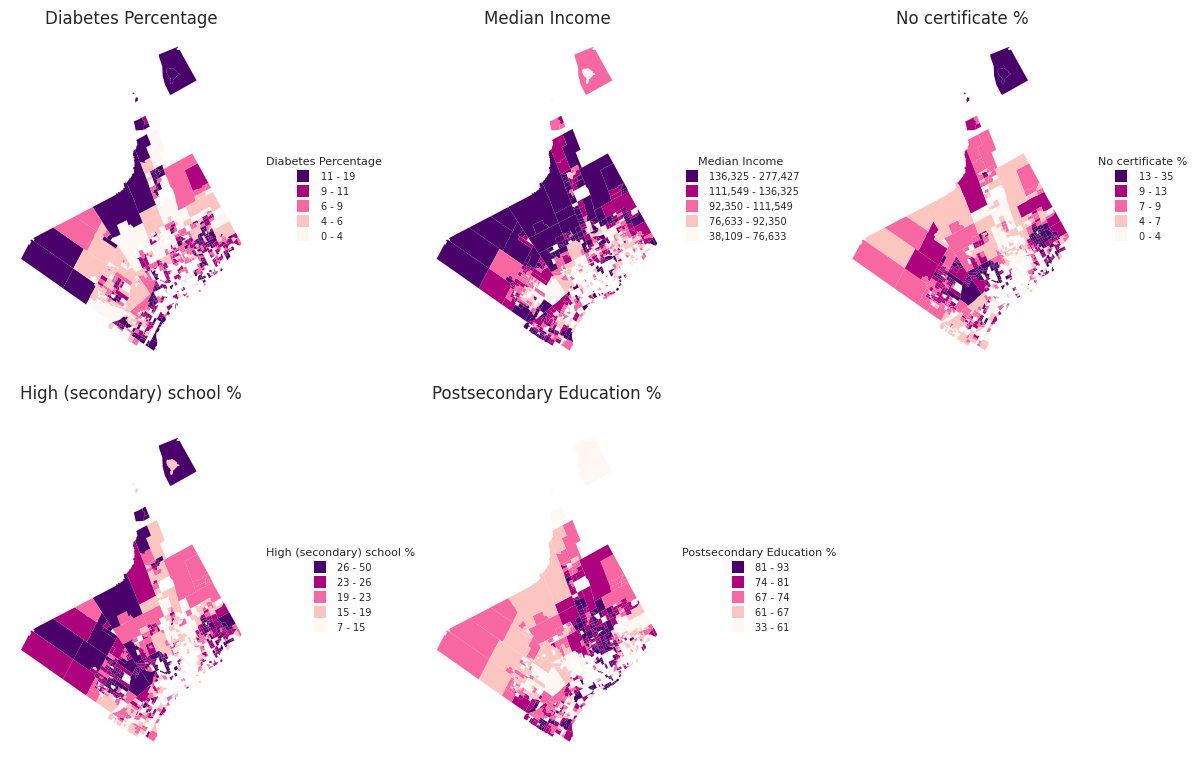

/tmp/ipykernel_3511/1333701602.py:122: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(db)
/usr/local/lib/python3.12/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 16 disconnected components.
  W.__init__(self, neighbors, ids=ids, **kw)


,Moran's I,P-value
Variable,,
Diabetes Percentage,0.498074,0.001
Median Income,0.512593,0.001
No certificate %,0.730801,0.001
High (secondary) school %,0.692552,0.001
Postsecondary Education %,0.763712,0.001


In [ ]:


# Read files
db = gpd.read_file(
    "zip+https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/census_tract_clipped.zip",
    engine="pyogrio"
)


vars_df = pd.read_csv(
    "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/merged_diabetes_income_education.csv"
)


# Make common join ID
db["CTUID"] = db["CTUID"].astype(str).str.strip()
vars_df["spatial_id"] = vars_df["spatial_id"].astype(str).str.strip()


# Merge tract polygons with variables
db = db.merge(vars_df, left_on="CTUID", right_on="spatial_id", how="inner")

# Rename income column for cleaner name
db = db.rename(columns={
    "Households by Income (Current Year) | Median Household Income (Current Year $), 2025": "Median Income"
})

# Variables to map

cluster_variables = [
    "Diabetes Percentage",
    "Median Income",
    "No certificate %",
    "High (secondary) school %",
    "Postsecondary Education %"
]


# Keep only complete rows
db = db.dropna(subset=cluster_variables).copy()


# Rename income column
db = db.rename(columns={
    "Households by Income (Current Year) | Median Household Income (Current Year $), 2025": "Median Income"
})


# Plot all variables
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(12, 8))
axs = axs.flatten()


for i, col in enumerate(cluster_variables):
    ax = axs[i]
    db.plot(
        column=col,
        ax=ax,
        scheme="Quantiles",
        linewidth=0,
        cmap="RdPu",
        legend=True,
        legend_kwds={
            "loc": "center left",
            "bbox_to_anchor": (1.02, 0.5),
            "fontsize": 7,
            "title": col,
            "title_fontsize": 8,
            "frameon": False,
            "fmt": "{:.0f}",
        }
    )

# reformat legend labels
    legend = ax.get_legend()
    if legend:
        handles = legend.legend_handles
        texts = legend.get_texts()

        # square markers and reformat labels
        for handle, text in zip(handles, texts):
            handle.set_marker("s")       # square
            handle.set_markersize(8)

            parts = text.get_text().split(",")
            if len(parts) == 2:
                try:
                    lo = f"{float(parts[0]):,.0f}"
                    hi = f"{float(parts[1]):,.0f}"
                    text.set_text(f"{lo} - {hi}")
                except ValueError:
                    pass

        # reverse order so highest is at top
        handles = handles[::-1]
        texts_str = [t.get_text() for t in texts][::-1]

        legend.remove()
        ax.legend(
            handles=handles,
            labels=texts_str,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            fontsize=7,
            title=col,
            title_fontsize=8,
            frameon=False,
        )

    ax.set_axis_off()
    ax.set_title(col)


# turn off any extra empty subplot(s)
for j in range(len(cluster_variables), len(axs)):
    axs[j].set_axis_off()


plt.tight_layout()
plt.show()


# Queen contiguity weights
w = Queen.from_dataframe(db)



# Moran's I for each variable
np.random.seed(12345)


mi_results = [
    Moran(db[variable], w) for variable in cluster_variables
]


mi_table = pd.DataFrame(
    [
        (variable, res.I, res.p_sim)
        for variable, res in zip(cluster_variables, mi_results)
    ],
    columns=["Variable", "Moran's I", "P-value"]
).set_index("Variable")


mi_table


In [ ]:
# ============================================================
# Spatial weights and spatial structure construction
# ============================================================

# extract all shapefile components

url = "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/census_tract_clipped.zip"
r = requests.get(url)

z = zipfile.ZipFile(io.BytesIO(r.content))
z.extractall("/content/ct_shapefile")

# Load the shapefile — this is a national file covering all of Canada
gdf = gpd.read_file("/content/ct_shapefile/lct_000b21a_e.shp")



# Filter to Toronto CMA only, starting with "535"

gdf_toronto = gdf[gdf["CTUID"].str.startswith("535")].copy()
gdf_toronto = gdf_toronto.reset_index(drop=True)

print("Toronto CMA tracts:", gdf_toronto.shape)


# Making one common join key from gdf_toronto and df_merged
df_merged["CT_KEY"]   = df_merged["GEO UID"].astype(str).str[3:]
gdf_toronto["CT_KEY"] = gdf_toronto["CTUID"].str[3:]

df_merged["CT_KEY"] = df_merged["GEO UID"].apply(lambda x: f"{float(x):.2f}"[3:])
gdf_toronto["CT_KEY"] = gdf_toronto["CTUID"].str[3:]


# Join the shapefile with the merged data

gdf_final = gdf_toronto.merge(
    df_merged,
    on="CT_KEY",
    how="left"
)

print("Shape after join:", gdf_final.shape)
gdf_final.head()



# Drop unmatched CTs [The 167 NaN rows are tracts in the shapefile that were excluded]

gdf_final = gdf_final.dropna(subset=["Total Education"]).copy()
gdf_final = gdf_final.reset_index(drop=True)

print("Final CT count:", gdf_final.shape[0])


# Build the Queen contiguity spatial weights matrix with row standardisation

w = Queen.from_dataframe(gdf_final)
w.transform = 'r'

print("Number of observations:", w.n)
print("Average number of neighbours:", w.mean_neighbors)
print("Min neighbours:", w.min_neighbors)
print("Max neighbours:", w.max_neighbors)



# Removing the island polygon

print("Island CT info:")
print(gdf_final.loc[65, ["CTUID", "CTNAME", "CDName"]])

gdf_final = gdf_final.drop(index=65).reset_index(drop=True)

# Rebuild the weights matrix without the island

w = Queen.from_dataframe(gdf_final)
w.transform = 'r'

print("Final number of observations:", w.n)
print("Fully connected:", w.component_labels.max() == 0)

Toronto CMA tracts: (1065, 6)
Shape after join: (1065, 25)
Final CT count: 1060


/tmp/ipykernel_3511/2254880211.py:57: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(gdf_final)
/usr/local/lib/python3.12/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 65.
  W.__init__(self, neighbors, ids=ids, **kw)
/tmp/ipykernel_3511/2254880211.py:76: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(gdf_final)


('WARNING: ', 65, ' is an island (no neighbors)')
Number of observations: 1060
Average number of neighbours: 6.613207547169812
Min neighbours: 0
Max neighbours: 18
Island CT info:
CTUID     5350002.00
CTNAME       0002.00
CDName       Toronto
Name: 65, dtype: object
Final number of observations: 1059
Fully connected: True


GLOBAL MORAN'S I RESULTS

Diabetes Percentage
  Moran's I  : 0.5278
  p-value    : 0.0010
  z-score    : 30.6896
  Significant: Yes

Median Income
  Moran's I  : 0.3967
  p-value    : 0.0010
  z-score    : 23.6683
  Significant: Yes

Postsecondary Education %
  Moran's I  : 0.7504
  p-value    : 0.0010
  z-score    : 43.6604
  Significant: Yes

No certificate %
  Moran's I  : 0.7083
  p-value    : 0.0010
  z-score    : 41.4723
  Significant: Yes

High (secondary) school %
  Moran's I  : 0.7015
  p-value    : 0.0010
  z-score    : 41.2617
  Significant: Yes


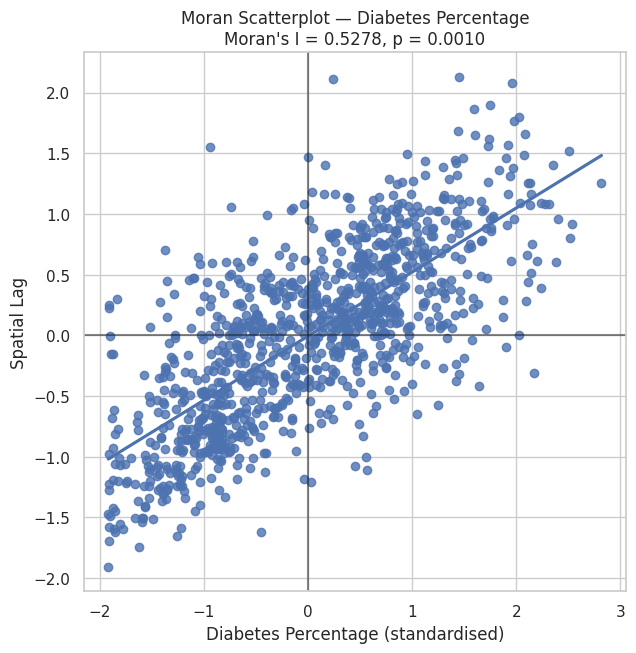

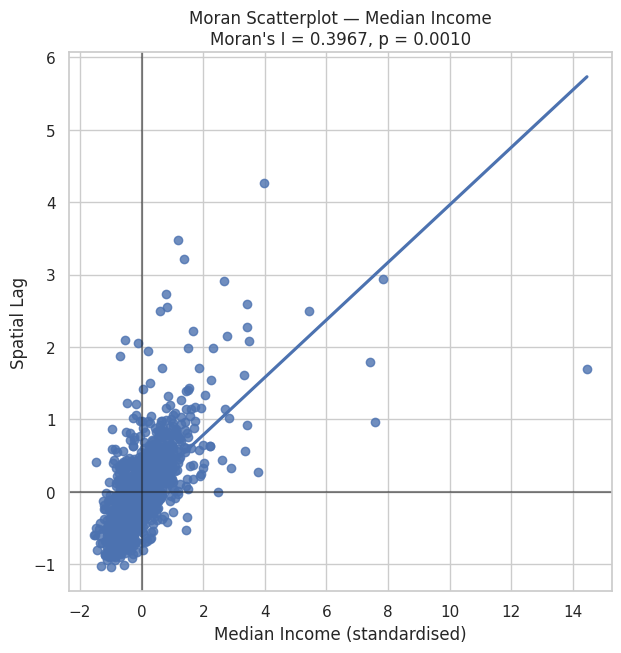

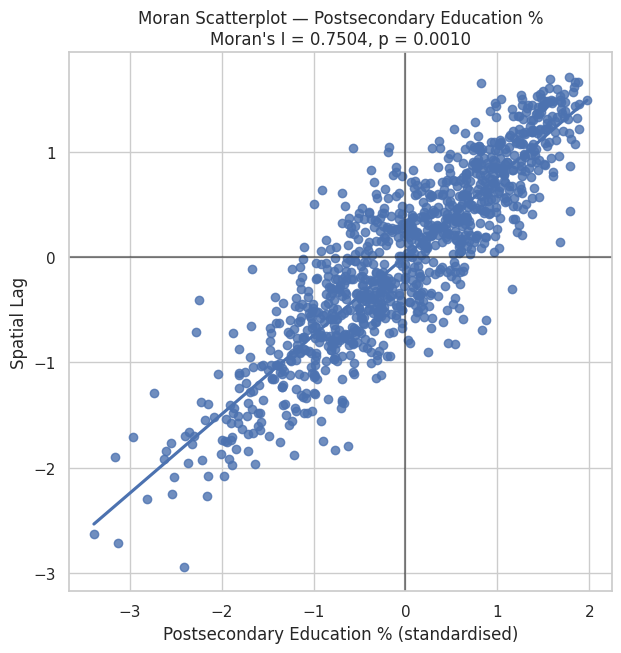

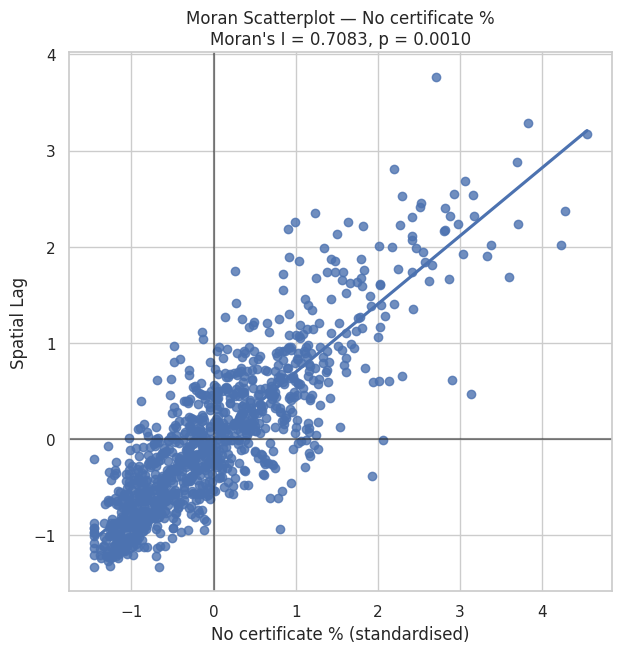

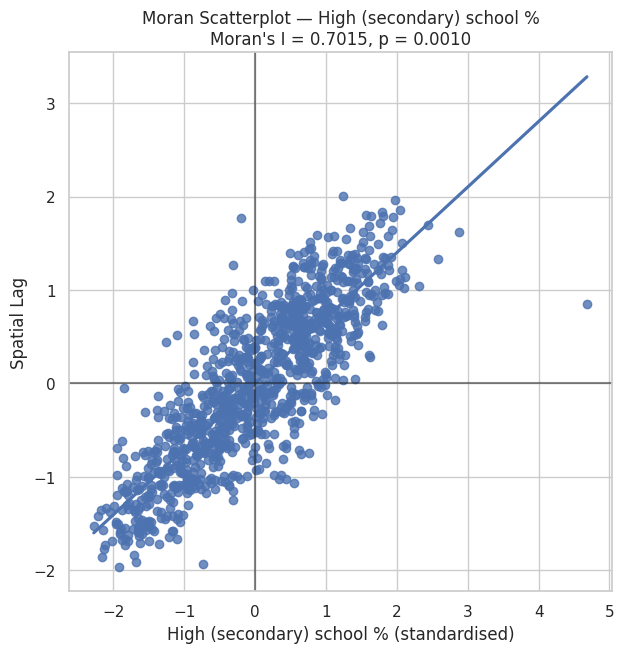


Diabetes Percentage
cluster
Non-Significant    629
LL (Cold Spot)     221
HH (Hot Spot)      185
HL (Outlier)        13
LH (Outlier)        11
Significant proportion: 0.4060

Median Income
cluster
Non-Significant    729
LL (Cold Spot)     219
HH (Hot Spot)       88
LH (Outlier)        13
HL (Outlier)        10
Significant proportion: 0.3116

Postsecondary Education %
cluster
Non-Significant    552
HH (Hot Spot)      269
LL (Cold Spot)     222
LH (Outlier)         9
HL (Outlier)         7
Significant proportion: 0.4788

No certificate %
cluster
Non-Significant    586
LL (Cold Spot)     283
HH (Hot Spot)      177
LH (Outlier)         9
HL (Outlier)         4
Significant proportion: 0.4466

High (secondary) school %
cluster
Non-Significant    541
HH (Hot Spot)      248
LL (Cold Spot)     243
LH (Outlier)        14
HL (Outlier)        13
Significant proportion: 0.4891


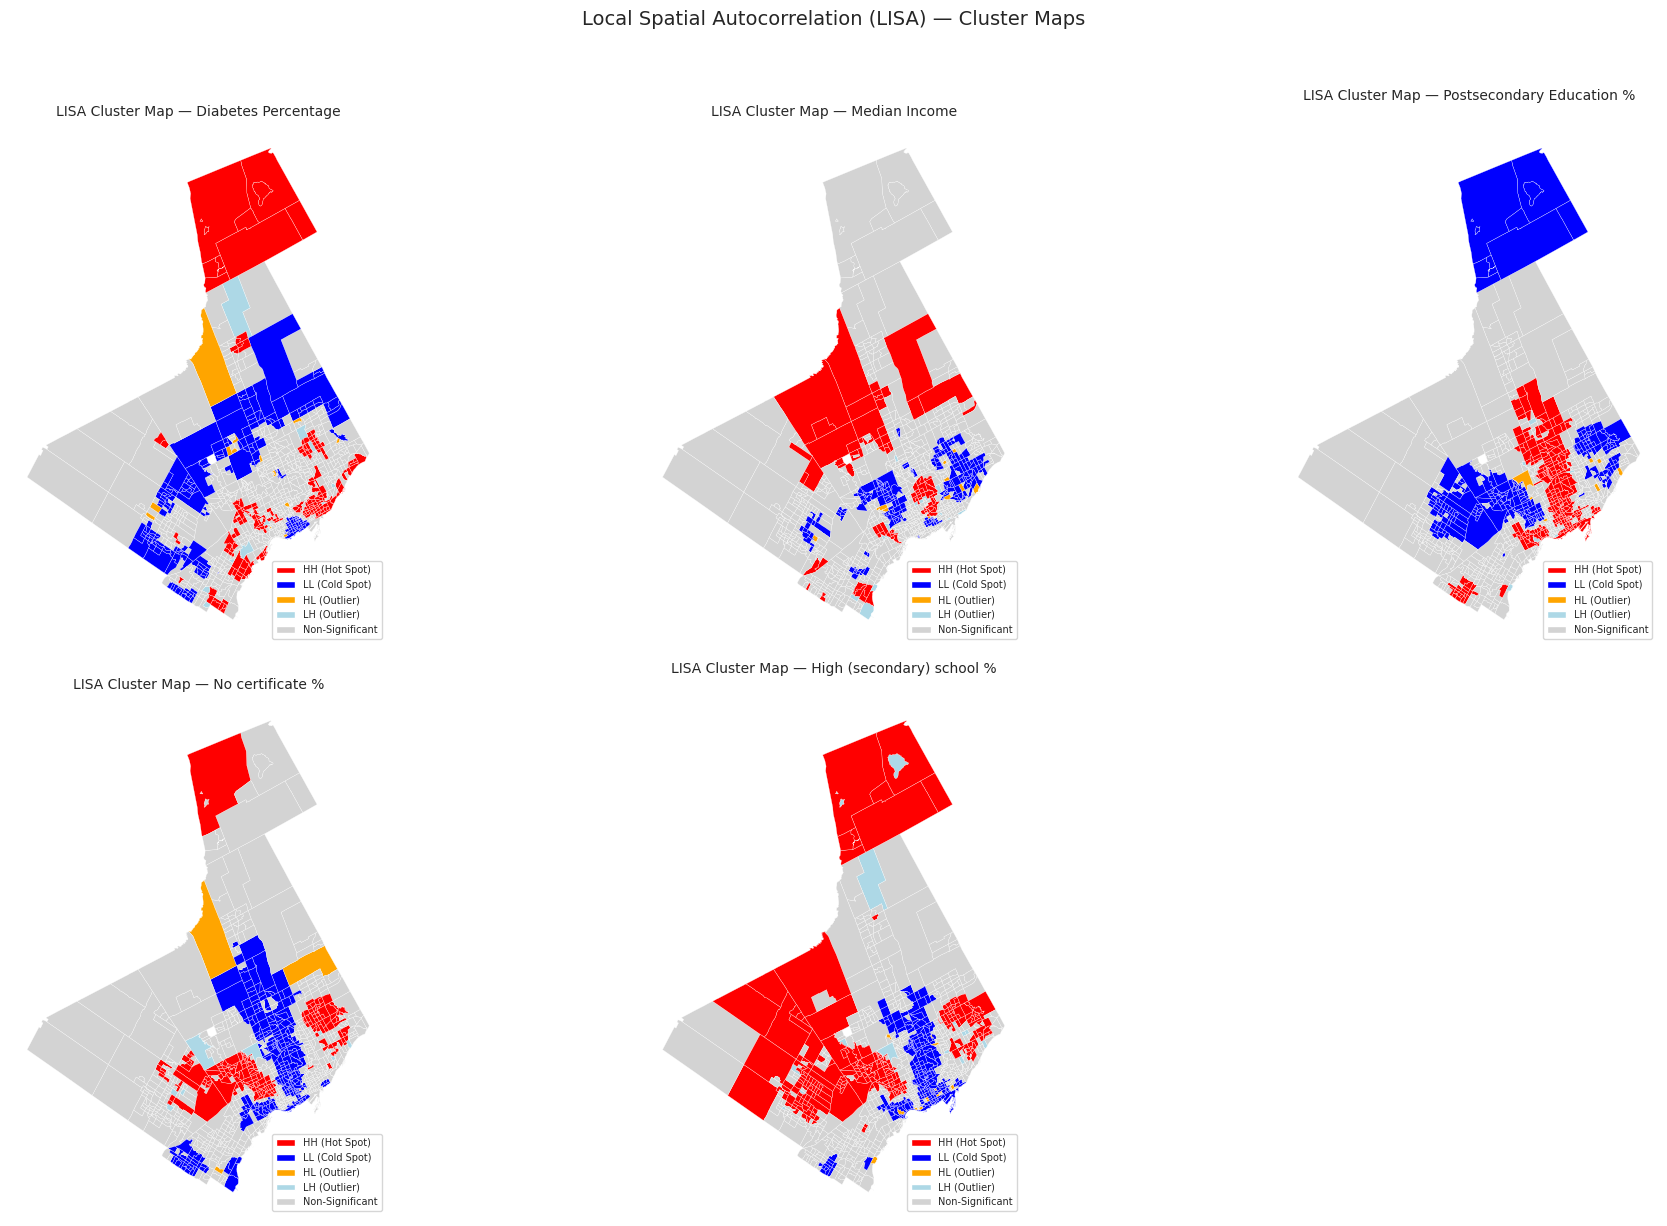

In [ ]:
# ============================================================
# Spatial autocorrelation
# ============================================================


# Rename income column in gdf_final if not already done
gdf_final = gdf_final.rename(columns={
    "Households by Income (Current Year) | Median Household Income (Current Year $), 2025": "Median Income"
}, errors="ignore")

variables = [
    "Diabetes Percentage",
    "Median Income",
    "Postsecondary Education %",
    "No certificate %",
    "High (secondary) school %",
]

colors = {
    "HH (Hot Spot)":   "red",
    "LL (Cold Spot)":  "blue",
    "HL (Outlier)":    "orange",
    "LH (Outlier)":   "lightblue",
    "Non-Significant": "lightgrey"
}

labels_map = {
    1: "HH (Hot Spot)",
    2: "LH (Outlier)",
    3: "LL (Cold Spot)",
    4: "HL (Outlier)"
}


# Global Moran's I

print("=" * 55)
print("GLOBAL MORAN'S I RESULTS")
print("=" * 55)

for var in variables:
    subset = gdf_final[[var, "geometry"]].dropna().copy().reset_index(drop=True)
    w_sub = Queen.from_dataframe(subset, use_index=False)
    w_sub.transform = "R"

    mi = Moran(subset[var], w_sub, permutations=999)

    print(f"\n{var}")
    print(f"  Moran's I  : {mi.I:.4f}")
    print(f"  p-value    : {mi.p_sim:.4f}")
    print(f"  z-score    : {mi.z_sim:.4f}")
    print(f"  Significant: {'Yes' if mi.p_sim < 0.05 else 'No'}")
    print("=" * 55)



# Moran Scatterplot
for var in variables:
    subset = gdf_final[[var, "geometry"]].dropna().copy().reset_index(drop=True)
    w_sub = Queen.from_dataframe(subset, use_index=False)
    w_sub.transform = "R"

    subset["var_std"]     = (subset[var] - subset[var].mean()) / subset[var].std()
    subset["var_std_lag"] = lag_spatial(w_sub, subset["var_std"])

    mi = Moran(subset[var], w_sub, permutations=999)

    f, ax = plt.subplots(1, figsize=(7, 7))
    sns.regplot(x="var_std", y="var_std_lag", data=subset, ci=None, ax=ax)
    plt.axvline(0, c="k", alpha=0.5)
    plt.axhline(0, c="k", alpha=0.5)
    ax.set_xlabel(f"{var} (standardised)")
    ax.set_ylabel("Spatial Lag")
    ax.set_title(f"Moran Scatterplot — {var}\nMoran's I = {mi.I:.4f}, p = {mi.p_sim:.4f}")
    plt.show()


# Local Moran's I LISA

lisa_subsets = {}

for var in variables:
    subset = gdf_final[[var, "geometry"]].dropna().copy().reset_index(drop=True)
    w_sub = Queen.from_dataframe(subset, use_index=False)
    w_sub.transform = "R"

    lisa = Moran_Local(subset[var], w_sub, permutations=999)

    subset["lisa_q"]  = lisa.q
    subset["lisa_p"]  = lisa.p_sim
    subset["sig"]     = subset["lisa_p"] < 0.05
    subset["cluster"] = "Non-Significant"
    subset.loc[subset["sig"], "cluster"] = (
        subset.loc[subset["sig"], "lisa_q"].map(labels_map)
    )

    lisa_subsets[var] = subset

    print(f"\n{var}")
    print(subset["cluster"].value_counts().to_string())
    print(f"Significant proportion: {subset['sig'].mean():.4f}")
    print("=" * 55)


# LISA cluster map


fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, var in enumerate(variables):
    subset = lisa_subsets[var].copy()
    subset["color"] = subset["cluster"].map(colors)
    subset.plot(color=subset["color"], ax=axes[i],
                linewidth=0.2, edgecolor="white")

    legend_elements = [
        mpatches.Patch(facecolor=v, label=k) for k, v in colors.items()
    ]
    axes[i].legend(handles=legend_elements, loc="lower right", fontsize=7)
    axes[i].set_title(f"LISA Cluster Map — {var}", fontsize=10)
    axes[i].axis("off")

axes[5].set_visible(False)

plt.suptitle("Local Spatial Autocorrelation (LISA) — Cluster Maps",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

GLOBAL BIVARIATE MORAN'S I RESULTS

Diabetes % × Median Income
  Moran's I  : -0.1166
  p-value    : 0.0010
  z-score    : -4.9264
  Significant: Yes

Diabetes % × Postsecondary Education %
  Moran's I  : -0.2100
  p-value    : 0.0010
  z-score    : -9.0605
  Significant: Yes

Diabetes % × No certificate %
  Moran's I  : 0.2012
  p-value    : 0.0010
  z-score    : 8.6902
  Significant: Yes

Diabetes % × High (secondary) school %
  Moran's I  : 0.1950
  p-value    : 0.0010
  z-score    : 8.4696
  Significant: Yes

Diabetes % × Median Income
cluster
Non-Significant                   722
High Diabetes / Low Neighbour     150
Low Diabetes / Low Neighbour       81
Low Diabetes / High Neighbour      71
High Diabetes / High Neighbour     35
Significant proportion: 0.3182

Diabetes % × Postsecondary Education %
cluster
Non-Significant                   549
Low Diabetes / High Neighbour     177
High Diabetes / Low Neighbour     137
High Diabetes / High Neighbour    104
Low Diabetes / Low Neighb

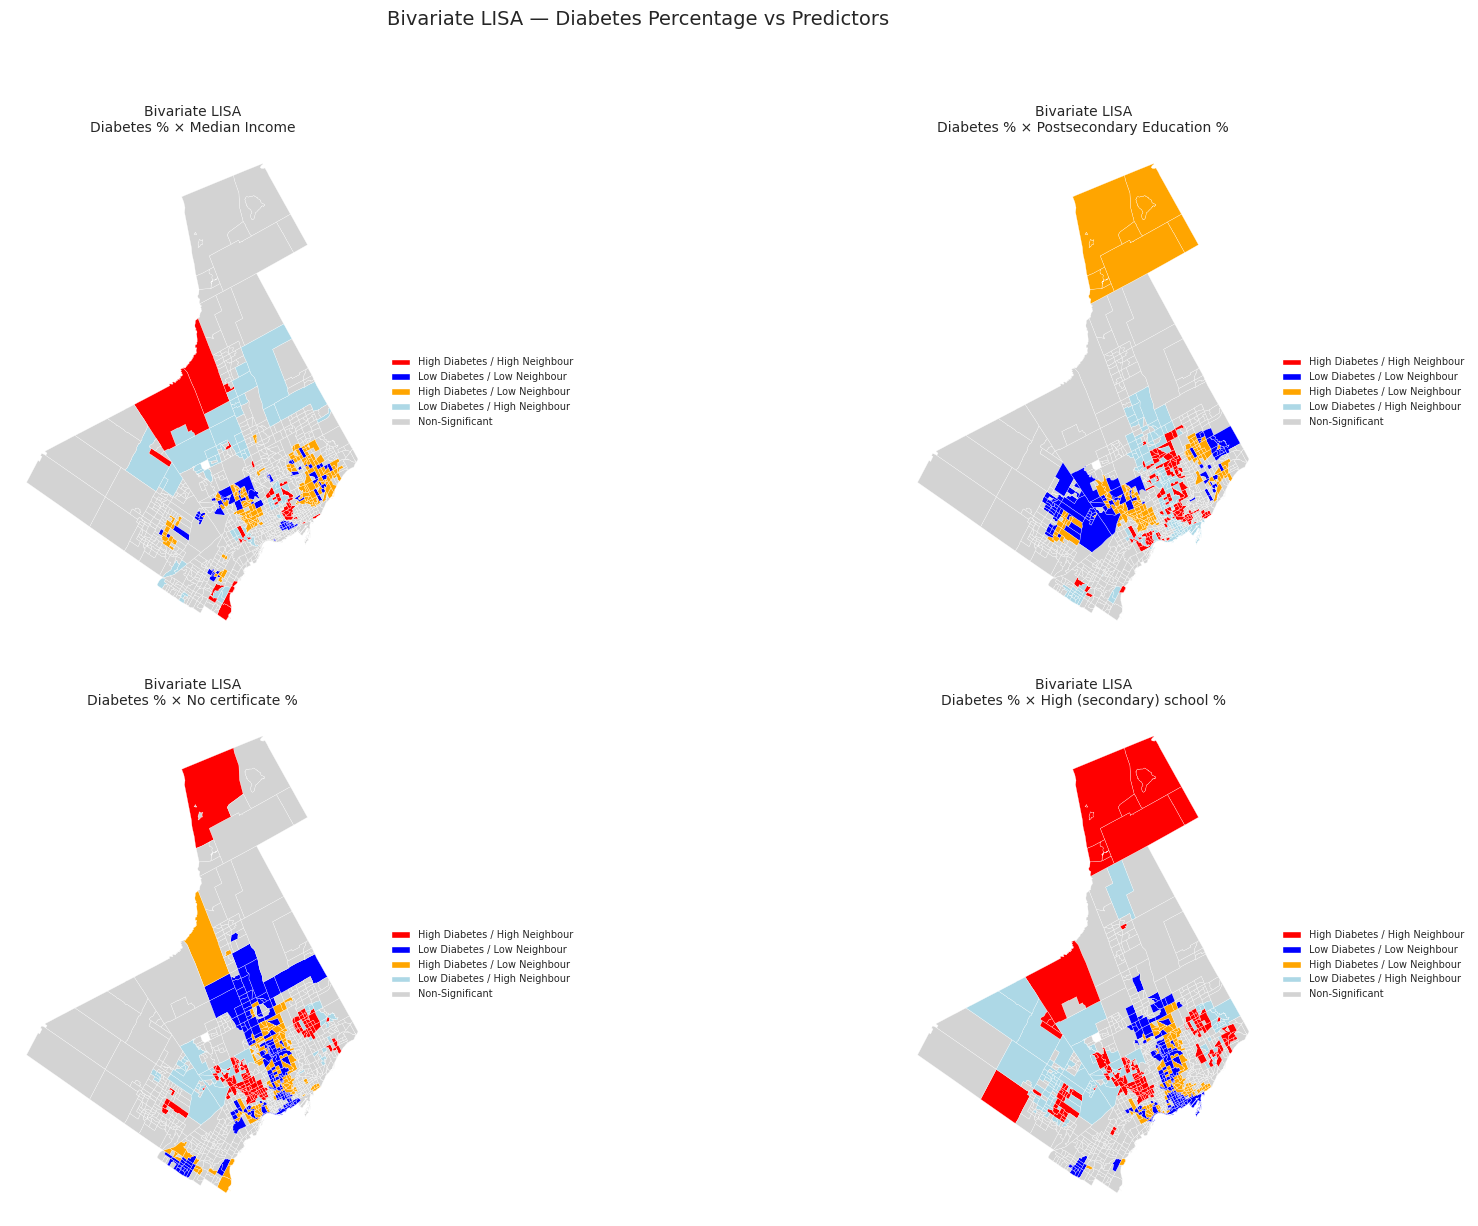

In [ ]:
# ============================================================
# Spatial autocorrelation part two
# ============================================================
# Bivarite Moran's I



bv_vars = [
    "Median Income",
    "Postsecondary Education %",
    "No certificate %",
    "High (secondary) school %"
]

colors_bv = {
    "High Diabetes / High Neighbour": "red",
    "Low Diabetes / Low Neighbour":   "blue",
    "High Diabetes / Low Neighbour":  "orange",
    "Low Diabetes / High Neighbour":  "lightblue",
    "Non-Significant":                "lightgrey"
}

labels_map_bv = {
    1: "High Diabetes / High Neighbour",
    2: "Low Diabetes / High Neighbour",
    3: "Low Diabetes / Low Neighbour",
    4: "High Diabetes / Low Neighbour"
}


# Global Bivariate Moran's I

subset_bv = gdf_final[["Diabetes Percentage"] + bv_vars + ["geometry"]].dropna().copy().reset_index(drop=True)
w_bv = Queen.from_dataframe(subset_bv, use_index=False)
w_bv.transform = "R"

x_diabetes = subset_bv["Diabetes Percentage"].values

print("=" * 55)
print("GLOBAL BIVARIATE MORAN'S I RESULTS")
print("=" * 55)

for var in bv_vars:
    bv = Moran_BV(x_diabetes, subset_bv[var].values, w_bv, permutations=999)
    print(f"\nDiabetes % × {var}")
    print(f"  Moran's I  : {bv.I:.4f}")
    print(f"  p-value    : {bv.p_sim:.4f}")
    print(f"  z-score    : {bv.z_sim:.4f}")
    print(f"  Significant: {'Yes' if bv.p_sim < 0.05 else 'No'}")
    print("=" * 55)


# Local Bivariate Moran's I (LISA)

lisa_bv_subsets = {}

for var in bv_vars:
    subset = gdf_final[["Diabetes Percentage", var, "geometry"]].dropna().copy().reset_index(drop=True)
    w_sub = Queen.from_dataframe(subset, use_index=False)
    w_sub.transform = "R"

    lisa_bv = Moran_Local_BV(
        subset["Diabetes Percentage"].values,
        subset[var].values,
        w_sub,
        permutations=999
    )

    subset["lisa_q"]  = lisa_bv.q
    subset["lisa_p"]  = lisa_bv.p_sim
    subset["sig"]     = subset["lisa_p"] < 0.05
    subset["cluster"] = "Non-Significant"
    subset.loc[subset["sig"], "cluster"] = (
        subset.loc[subset["sig"], "lisa_q"].map(labels_map_bv)
    )

    lisa_bv_subsets[var] = subset

    print(f"\nDiabetes % × {var}")
    print(subset["cluster"].value_counts().to_string())
    print(f"Significant proportion: {subset['sig'].mean():.4f}")
    print("=" * 55)


# Bivariate LISA Cluster Maps

fig, axes = plt.subplots(2, 2, figsize=(20, 12))
axes = axes.flatten()

for i, var in enumerate(bv_vars):
    subset = lisa_bv_subsets[var].copy()
    subset["color"] = subset["cluster"].map(colors_bv)
    subset.plot(color=subset["color"], ax=axes[i],
                linewidth=0.2, edgecolor="white")

    legend_elements = [
        mpatches.Patch(facecolor=v, label=k) for k, v in colors_bv.items()
    ]
    axes[i].legend(
        handles=legend_elements,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=7,
        frameon=False
    )
    axes[i].set_title(f"Bivariate LISA\nDiabetes % × {var}", fontsize=10)
    axes[i].axis("off")

plt.suptitle("Bivariate LISA — Diabetes Percentage vs Predictors",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

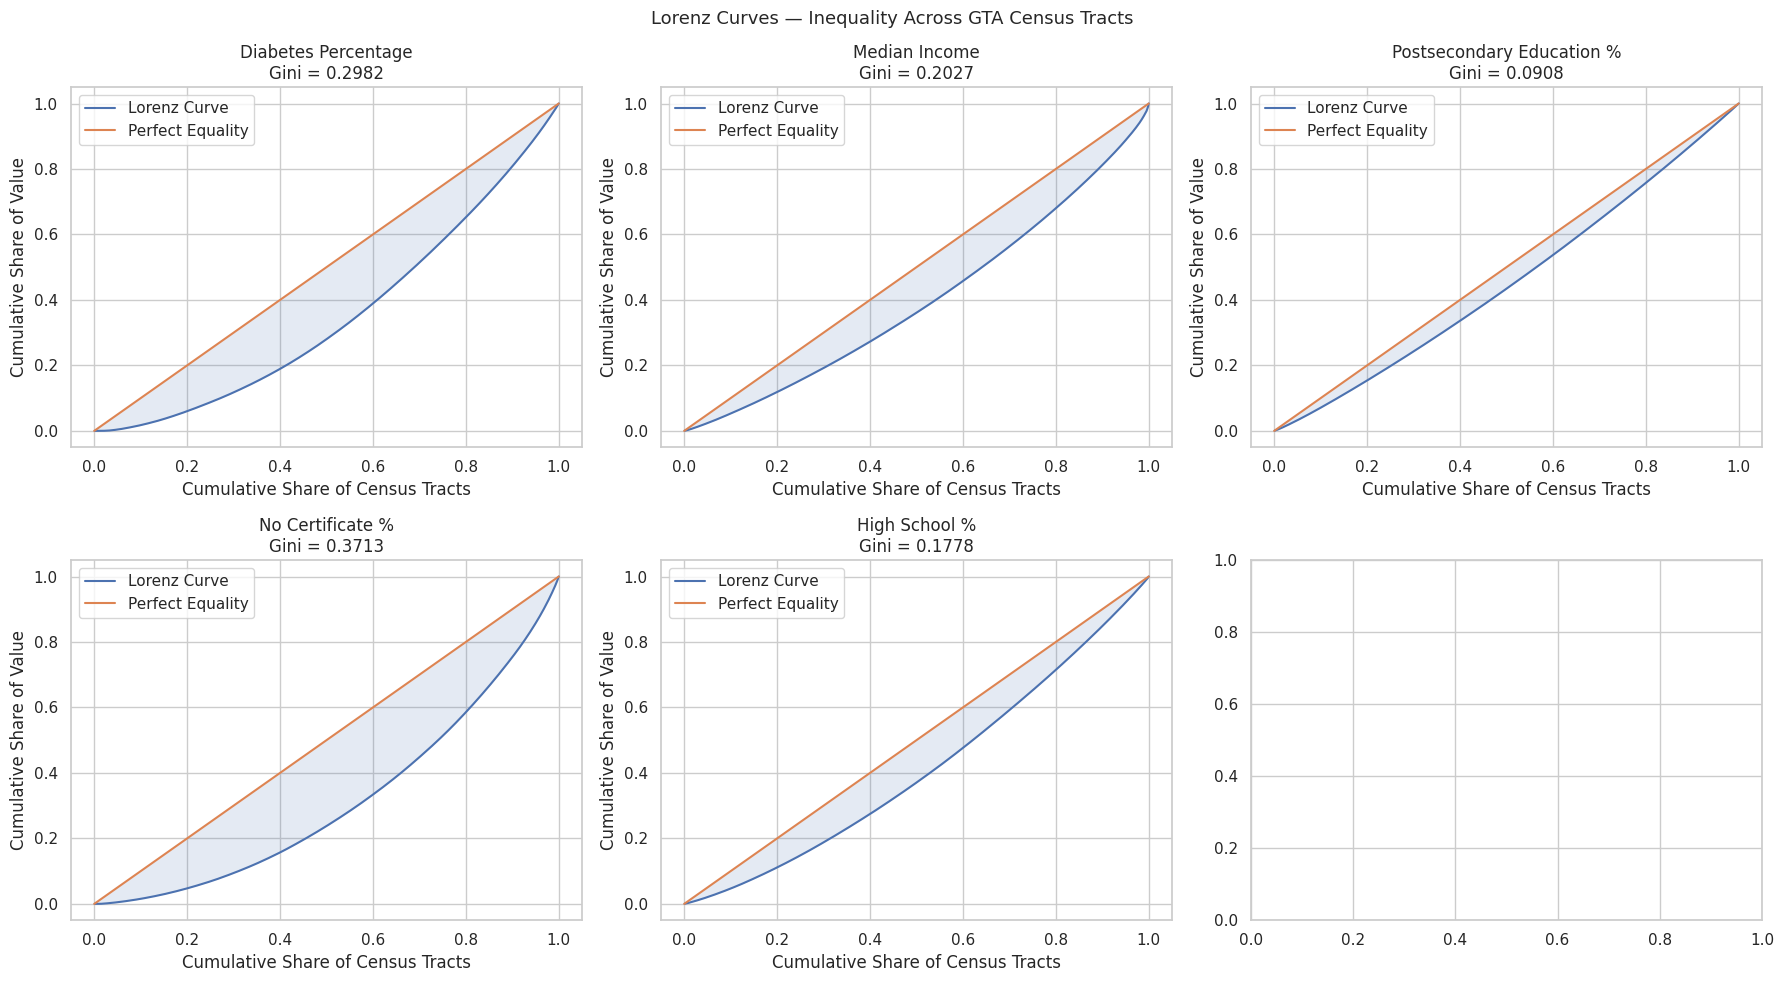

Gini Coefficients
  Diabetes Percentage: 0.2982
  Median Income: 0.2027
  Postsecondary Education %: 0.0908
  No Certificate %: 0.3713
  High School %: 0.1778


In [ ]:

# Inequality Analysis — Gini Index + Lorenz Curve

inequality_vars = {
    "Diabetes Percentage":       gdf_final["Diabetes Percentage"].dropna().values,
    "Median Income":             gdf_final["Median Income"].dropna().values,
    "Postsecondary Education %": gdf_final["Postsecondary Education %"].dropna().values,
    "No Certificate %":          gdf_final["No certificate %"].dropna().values,
    "High School %":             gdf_final["High (secondary) school %"].dropna().values
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (label, y) in zip(axes, inequality_vars.items()):
    n = len(y)


    y_sorted = np.sort(y)
    pop_share = np.arange(1, n + 1) / n
    inc_share = (y_sorted / y_sorted.sum()).cumsum()


    gini = Gini(y).g

    ax.plot(pop_share, inc_share, label="Lorenz Curve")
    ax.plot([0, 1], [0, 1], label="Perfect Equality")
    ax.fill_between(pop_share, inc_share, pop_share, alpha=0.15)
    ax.legend()
    ax.set_title(f"{label}\nGini = {gini:.4f}")
    ax.set_xlabel("Cumulative Share of Census Tracts")
    ax.set_ylabel("Cumulative Share of Value")

plt.suptitle("Lorenz Curves — Inequality Across GTA Census Tracts", fontsize=13)
plt.tight_layout()
plt.show()


print("Gini Coefficients")
print("=" * 40)
for label, y in inequality_vars.items():
    print(f"  {label}: {Gini(y).g:.4f}")

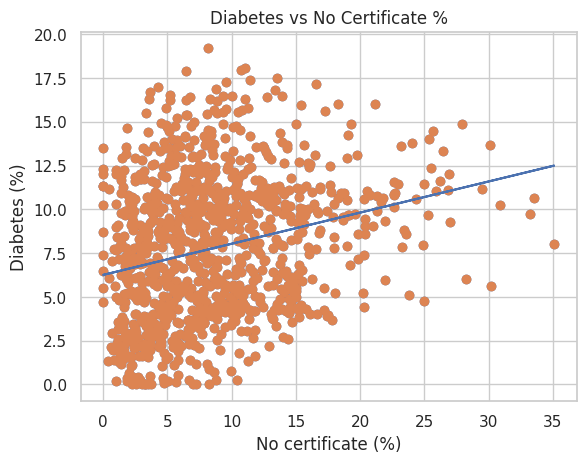

Correlation: 0.25670645608635884


In [ ]:
# Correlation Analysis of Diabetes Prevalence vs No certication percentage

import matplotlib.pyplot as plt

# Diabetes % vs No certificate %
x = gdf_final["No certificate %"]
y = gdf_final["Diabetes Percentage"]
plt.scatter(
    x, y
)

# scatter plot
plt.scatter(x, y)

# trend line
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, p(x))

# correlation
r = np.corrcoef(x, y)[0, 1]

plt.xlabel("No certificate (%)")
plt.ylabel("Diabetes (%)")
plt.title("Diabetes vs No Certificate %")
plt.show()
print("Correlation:",r)


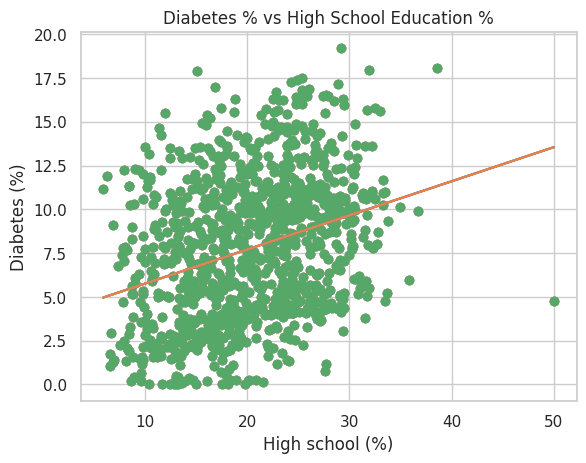

Correlation: 0.30484123489577575


In [ ]:
# Correlation Analysis of Diabetes Prevalence vs High school Education %


x = gdf_final["High (secondary) school %"]
y = gdf_final["Diabetes Percentage"]
plt.scatter(
    x, y
)

# scatter plot
plt.scatter(x, y)

# trend line
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, p(x))

# correlation
r = np.corrcoef(x, y)[0, 1]


plt.xlabel("High school (%)")
plt.ylabel("Diabetes (%)")
plt.scatter(x, y)

# trend line
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, p(x))

# correlation
r = np.corrcoef(x, y)[0, 1]


plt.title("Diabetes % vs High School Education %")
plt.show()
print("Correlation:",r)


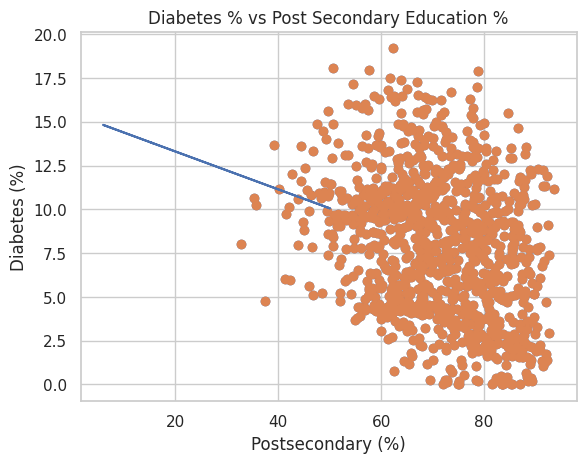

Correlation: 0.30484123489577575


In [ ]:
# Correlation Analysis of Diabetes Prevalence vs Postsecondary %

# independent variable
x_axis = gdf_final["Postsecondary Education %"]

# dependent variable
y_axis = gdf_final["Diabetes Percentage"]
plt.scatter(
    x_axis, y_axis
)

# scatter plot
plt.scatter(x_axis, y_axis)

# trend line
z = np.polyfit(x_axis, y_axis, 1)
p = np.poly1d(z)
plt.plot(x, p(x))

# correlation
r = np.corrcoef(x, y)[0, 1]


plt.xlabel("Postsecondary (%)")
plt.ylabel("Diabetes (%)")
plt.title("Diabetes % vs Post Secondary Education %")
plt.show()
print("Correlation:",r)


In [ ]:
# Spatial Regression of Education

from pysal.model import spreg
from esda.moran import Moran

# independent variables
x_axis = gdf_final[[
    "No certificate %",
    "High (secondary) school %",
    "Postsecondary Education %"
]].values


# dependent variable
y_axis = gdf_final[["Diabetes Percentage"]].values

# make the spatial weight matrix 'w' from gdf_final to match with x and y


#OLS Regression
m_ols = spreg.OLS(y_axis, x_axis,
    name_y="Diabetes",
    name_x=["No certificate %", "High (secondary) school %", "Postsecondary Education %"]
)

# summary of OLS
print(m_ols.summary)



REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :        None
Dependent Variable  :    Diabetes                Number of Observations:        1059
Mean dependent var  :      7.7712                Number of Variables   :           4
S.D. dependent var  :      4.0511                Degrees of Freedom    :        1055
R-squared           :      0.0995
Adjusted R-squared  :      0.0969
Sum squared residual:     15635.9                F-statistic           :     38.8440
Sigma-square        :      14.821                Prob(F-statistic)     :   8.208e-24
S.E. of regression  :       3.850                Log likelihood        :   -2928.198
Sigma-square ML     :      14.765                Akaike info criterion :    5864.396
S.E of regression ML:      3.8425                Schwarz criterion     :    5884.256

-----------------

In [ ]:
# # Spatial Regression of Recreational Activities

# from pysal.model import spreg
# from esda.moran import Moran



# from pysal.model import spreg

# # dependent variable
# y_axis = gdf_joined[["diabetes_pct"]].values

# # independent variable (recreational spaces)
# x_axis = gdf_joined[["num_spaces"]].values


# # OLS Regression
# m_ols_rec = spreg.OLS(
#     y_axis,
#     x_axis,
#     name_y="Diabetes",
#     name_x=["Recreational spaces"]
# )

# print(m_ols_rec.summary)

In [ ]:
# Spatial Error Model in Education


# import Queen
from libpysal.weights import Queen
w = Queen.from_dataframe(gdf_final, use_index=False)

#  row standardization
w.transform = 'r'

# independent variable
x_axis = gdf_final[[
    "No certificate %",
    "High (secondary) school %",
    "Postsecondary Education %"
]].values


# dependent variable
y_axis = gdf_final[["Diabetes Percentage"]].values


# Spatial Error Model
# neighboring areas act similar due to hidden spatial factors

m7 = spreg.GM_Error_Het(
    # Dependent variable
    y_axis,
    # Independent variables
    x_axis,

    # spatial weights
    w = w,
    # Dependent variable name
    name_y="Diabetes Percentage",
    # Independent variables names
    name_x=[
        "No certificate %",
        "High (secondary) school %",
        "Postsecondary Education %"
    ]
)

print(m7.summary)

GM_Error_Het
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GM SPATIALLY WEIGHTED LEAST SQUARES (HET)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :Diabetes Percentage                Number of Observations:        1059
Mean dependent var  :      7.7712                Number of Variables   :           4
S.D. dependent var  :      4.0511                Degrees of Freedom    :        1055
Pseudo R-squared    :      0.0985
N. of iterations    :           1                Step1c computed       :          No

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        97.13490        12.21606         7.95141         0.00000
    No certi

In [ ]:
# # Spatial Error Model in Recreational Activities

# # Recreate the spatial weights matrix 'w' from 'gdf_joined' for consistency
# # This step is necessary because 'w' might have been overwritten by a previous
# # cell's execution, leading to a dimension mismatch.
# from libpysal.weights import Queen # Ensure Queen is imported here if not global
# w = Queen.from_dataframe(gdf_joined, use_index=False)
# w.transform = 'r' # Ensure row standardization as done previously

# # Redefine dependent variable from gdf_joined
# y_axis = gdf_joined[["diabetes_pct"]].values

# # Redefine independent variable (recreational spaces) from gdf_joined
# x_axis = gdf_joined[["num_spaces"]].values

# # Spatial Error Model

# m8 = spreg.GM_Error_Het(
#     # Dependent variable
#     y_axis,
#     # Independent variables
#     x_axis,
#     # Spatial weights matrix, used Queens contiguity as the neighbours share
#     # borders or corners, based on actual geography
#     w = w,
#     # Dependent variable name
#     name_y="diabetes_pct", # Corrected name_y to match dependent variable 'y_axis'
#     # Independent variables names
#     name_x=["num_spaces"] # Corrected name_x to be a list of variable names from 'x_axis'
# )

# print(m8.summary)

In [ ]:
# Spatial Lag Model in Education

# import queen
from libpysal.weights import Queen
w = Queen.from_dataframe(gdf_final, use_index=False)

# standardize
w.transform = 'r'

# independent variable
x_axis = gdf_final[[
    "No certificate %",
    "High (secondary) school %",
    "Postsecondary Education %"
]].values

# dependent variable
y_axis = gdf_final[["Diabetes Percentage"]].values



# Spatial Lag Model
# nearby areas are affected by each other so they act similar

m_lag = spreg.GM_Lag(
    y_axis,
    x_axis,
    w=w,
    name_y= "Diabetes Percentage"
)

print(m_lag.summary)

GM_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :Diabetes Percentage                Number of Observations:        1059
Mean dependent var  :      7.7712                Number of Variables   :           5
S.D. dependent var  :      4.0511                Degrees of Freedom    :        1054
Pseudo R-squared    :      0.2281
Spatial Pseudo R-squared:  0.0964

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        65.69917        24.25946         2.70819         0.00677
               var_1        -0.59551         0.24926        -2.38917         0.

In [ ]:
# # Spatial Lag Model in Recreational Activities

# m_lag1 = spreg.GM_Lag(
#     y_axis,
#     x_axis,
#     w=w,
#     name_y= "diabetes_pct"
#     # Independent variables names - removed due to library bug
#     # name_x= ["num_spaces"]

# )

# print(m_lag1.summary)

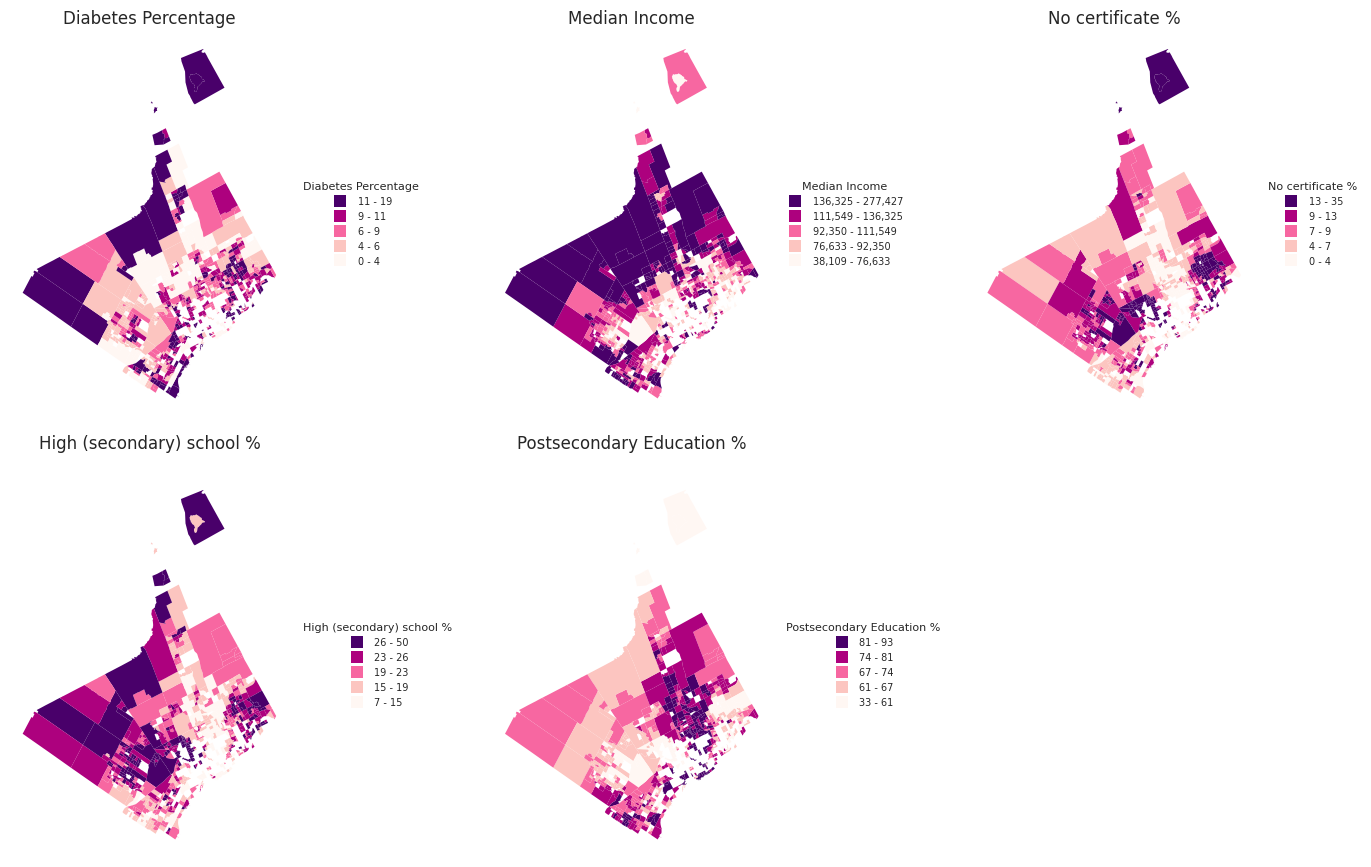

First five labels:
[0 2 2 0 3]


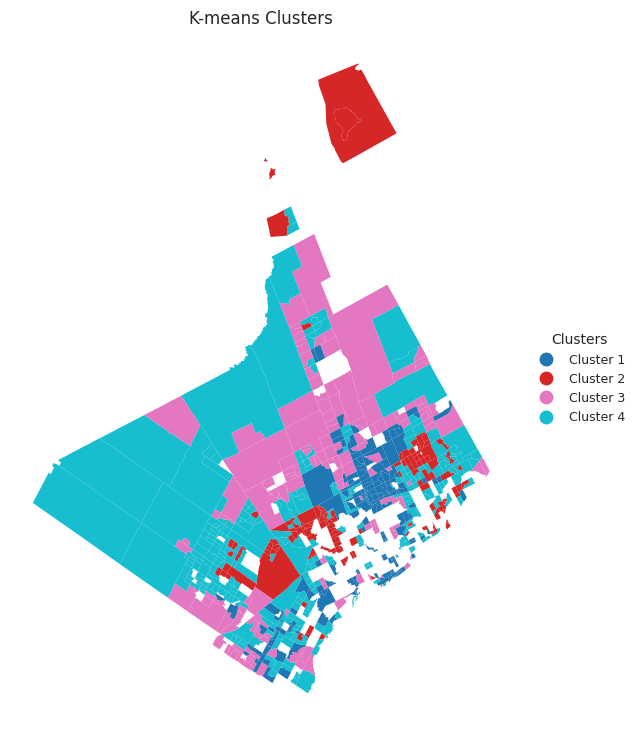

Cluster sizes:
k4cls
0    188
1    129
2    153
3    310
dtype: int64

Cluster means:
k4cls                              0          1           2          3
Diabetes Percentage            6.514      9.595       3.786      8.751
Median Income              99840.994  75268.304  160639.282  99359.670
No certificate %               3.907     18.850       4.674      9.763
High (secondary) school %     14.537     28.165      16.924     23.879
Postsecondary Education %     81.528     53.047      78.382     66.353


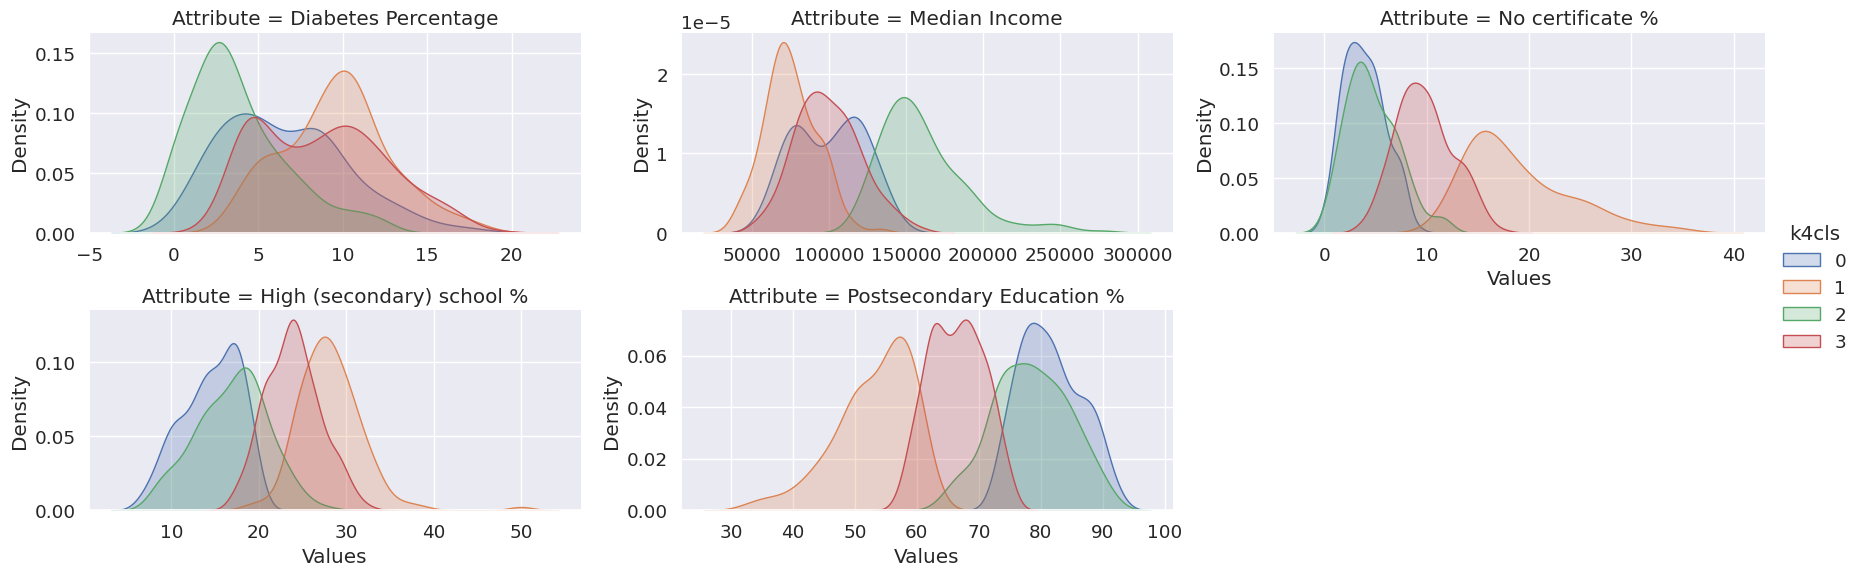

In [ ]:
import pandas
import geopandas
import matplotlib.pyplot as plt
import numpy
import seaborn

from sklearn.preprocessing import robust_scale
from sklearn.cluster import KMeans
from sklearn import metrics
# this is for k-means algorithm
db = geopandas.read_file(
    "zip+https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/census_tract_clipped.zip",
    engine="pyogrio"
)

vars_df = pandas.read_csv(
    "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/merged_diabetes_income_education.csv"
)

# validate and make join keys the same type of value
db["CTUID"] = db["CTUID"].astype(str).str.strip()
vars_df["spatial_id"] = vars_df["spatial_id"].astype(str).str.strip()

# merge the tract polygons with the layers
db = db.merge(vars_df, left_on="CTUID", right_on="spatial_id", how="left")


db = db.rename(columns={
    "Households by Income (Current Year) | Median Household Income (Current Year $), 2025": "Median Income"
})


cluster_variables = [
    "Diabetes Percentage",
    "Median Income",
    "No certificate %",
    "High (secondary) school %",
    "Postsecondary Education %"
]


db = db.dropna(subset=cluster_variables).copy()

# plot
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(14, 9))
axs = axs.flatten()

for i, col in enumerate(cluster_variables):
    ax = axs[i]

    db.plot(
        column=col,
        ax=ax,
        scheme="Quantiles",
        linewidth=0,
        cmap="RdPu",
        legend=True,
        legend_kwds={
            "loc": "center left",
            "bbox_to_anchor": (1.02, 0.5),
            "fontsize": 7,
            "title": col,
            "title_fontsize": 8,
            "frameon": False,
            "fmt": "{:.0f}"
        }
    )

    legend = ax.get_legend()
    if legend:
        handles = legend.legend_handles
        texts = legend.get_texts()

        for handle, text in zip(handles, texts):
            handle.set_marker("s")
            handle.set_markersize(8)

            parts = text.get_text().split(",")
            if len(parts) == 2:
                try:
                    lo = f"{float(parts[0]):,.0f}"
                    hi = f"{float(parts[1]):,.0f}"
                    text.set_text(f"{lo} - {hi}")
                except ValueError:
                    pass

        handles = handles[::-1]
        texts_str = [t.get_text() for t in texts][::-1]

        legend.remove()
        ax.legend(
            handles=handles,
            labels=texts_str,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            fontsize=7,
            title=col,
            title_fontsize=8,
            frameon=False
        )

    ax.set_axis_off()
    ax.set_title(col)

for j in range(len(cluster_variables), len(axs)):
    axs[j].set_axis_off()

plt.tight_layout()
plt.show()

# normalize variables
db_scaled = robust_scale(db[cluster_variables])

# run k-means with 4 clusters
numpy.random.seed(1234)
kmeans = KMeans(n_clusters=4, random_state=1234, n_init=10)
k4cls = kmeans.fit(db_scaled)

print("First five labels:")
print(k4cls.labels_[:5])

# add cluster label
db["k4cls"] = k4cls.labels_

cluster_names = {
    0: "Cluster 1",
    1: "Cluster 2",
    2: "Cluster 3",
    3: "Cluster 4"
}

db["k4cls_label"] = db["k4cls"].map(cluster_names)

# plot cluster map
f, ax = plt.subplots(1, figsize=(9, 9))

db.plot(
    column="k4cls_label",
    categorical=True,
    legend=True,
    linewidth=0,
    ax=ax,
    legend_kwds={
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5),
        "fontsize": 9,
        "title": "Clusters",
        "title_fontsize": 10,
        "frameon": False
    }
)

ax.set_axis_off()
ax.set_title("K-means Clusters")
plt.show()

# cluster sizes
k4sizes = db.groupby("k4cls").size()
print("Cluster sizes:")
print(k4sizes)

# cluster means
k4means = db.groupby("k4cls")[cluster_variables].mean()
print("\nCluster means:")
print(k4means.T.round(3))

# tidy plot  data
tidy_db = db.set_index("k4cls")
tidy_db = tidy_db[cluster_variables]
tidy_db = tidy_db.stack()
tidy_db = tidy_db.reset_index()
tidy_db = tidy_db.rename(columns={"level_1": "Attribute", 0: "Values"})

# density ploy
seaborn.set(font_scale=1.2)

facets = seaborn.FacetGrid(
    data=tidy_db,
    col="Attribute",
    hue="k4cls",
    sharey=False,
    sharex=False,
    aspect=2,
    col_wrap=3,
)

facets.map(seaborn.kdeplot, "Values", fill=True).add_legend()
plt.show()


In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.preprocessing import robust_scale
from sklearn.cluster import AgglomerativeClustering
from libpysal.weights import Queen

# AHC CLUSTERING
cts = gpd.read_file(
    "zip+https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/census_tract_clipped.zip",
    engine="pyogrio"
)

vars_df = pd.read_csv(
    "https://raw.githubusercontent.com/seven143143/GGR376-Final-Project/main/merged_diabetes_income_education.csv"
)

# 1: join keys
cts["CTUID"] = cts["CTUID"].astype(str).str.strip()
vars_df["spatial_id"] = vars_df["spatial_id"].astype(str).str.strip()


# merge
db = cts.merge(vars_df, left_on="CTUID", right_on="spatial_id", how="inner")

print(db.shape)
db.head()

cluster_variables = [
    "Diabetes Percentage",
    "Households by Income (Current Year) | Median Household Income (Current Year $), 2025",
    "No certificate %",
    "High (secondary) school %",
    "Postsecondary Education %"
]

db = db.dropna(subset=cluster_variables).copy()

# scale
db_scaled = robust_scale(db[cluster_variables])

# ward clustering
model = AgglomerativeClustering(
    linkage="ward",
    n_clusters=4
)

model.fit(db_scaled)
db["cluster"] = model.labels_

kmeans = KMeans(n_clusters=3)

# Set the seed for reproducibility
numpy.random.seed(1234)

# Run K-Means algorithm
k3cls = kmeans.fit(db_scaled)

(783, 24)
